# 3 · Classifying whole movements from summary features (option 1)

Unit = one movement (IBL `wheelMoves`, motion between two stillness periods); every movement gets exactly one class.
Each movement is described by ~10 numbers computed from its minimum-jerk primitives (`cache_primitives.py`) and its velocity, then clustered with a Gaussian mixture, pooled over all mice (features z-scored once on the pooled data, never per session or mouse).

**Direction** is taken out of the features: every movement is described relative to the direction of its first primitive, and that direction is kept as a separate label. So a left and a right "push + correction" share a class.

| feature | meaning |
|---|---|
| `log_dur` | log10 movement duration (s) |
| `log_path` | log10 total path, Σ\|D\| (rad) |
| `net_ratio` | net displacement / path, in the first primitive's direction: 1 = all one way, 0 = back where it started, < 0 = ends the other way |
| `log_n` | log2 number of primitives |
| `rev_rate` | reversals per primitive transition (0 if one primitive) |
| `first_share` | \|D\| of the first primitive / path: 1 = one ballistic push |
| `max_share` | \|D\| of the largest primitive / path |
| `log_first_T` | log10 duration of the first primitive (s) |
| `log_peak` | log10 peak speed (rad/s) |
| `overlap` | mean overlap of consecutive primitives (s; < 0 = gap) |

Data, kept small: 6 mice from 6 labs, first / middle / last training session each. K fixed at 20.

*Archived (2026-11-05): an approach that was not taken forward. Kept for reference; outputs are from the original run.*

In [1]:
import sys; sys.path.insert(0, '..')   # archived: the modules live one folder up
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
import wheel_states as ws, primitives as pr

PDIR = ws.DM_DIR.parent / 'wheel_primitives'
MICE = ['CSHL049', 'UCLA017', 'ZFM-01592', 'NYU-11', 'SWC_043', 'ibl_witten_27']
K = 20
man = ws.manifest()

def movement_features(mv, p, dm):
    p = p[p.D.abs() > 1e-3].sort_values(['movement', 'start'])
    t, v = dm.times.values, dm.velocity.values
    rows = []
    for m, q in p.groupby('movement'):
        D, s, d = q.D.values, q.start.values, q.duration.values
        d0 = np.sign(D[0])
        path = np.abs(D).sum()
        on, off = mv.onset[m], mv.offset[m]
        i0, i1 = np.searchsorted(t, [on, off])
        rows.append(dict(movement=m, direction=int(d0), n=len(D),
                         log_dur=np.log10(off - on), log_path=np.log10(path),
                         net_ratio=d0 * D.sum() / path, log_n=np.log2(len(D)),
                         rev_rate=np.mean(np.sign(D[1:]) != np.sign(D[:-1])) if len(D) > 1 else 0.,
                         first_share=abs(D[0]) / path, max_share=np.abs(D).max() / path,
                         log_first_T=np.log10(d[0]), log_peak=np.log10(np.abs(v[i0:i1 + 1]).max() + 1e-3),
                         overlap=np.mean((s[:-1] + d[:-1]) - s[1:]) if len(D) > 1 else 0.))
    f = pd.DataFrame(rows).set_index('movement')
    return mv.join(f, how='inner')

FEATS = ['log_dur', 'log_path', 'net_ratio', 'log_n', 'rev_rate', 'first_share', 'max_share',
         'log_first_T', 'log_peak', 'overlap']
M, PR, DM = [], {}, {}
for mouse in MICE:
    m = man.query('mouse == @mouse').sort_values('session_index')
    for stage, (_, r) in zip(['first', 'middle', 'last'], m.iloc[[0, len(m) // 2, -1]].iterrows()):
        mv = pd.read_parquet(PDIR / f'movements_{r.eid}_{mouse}')
        p = pd.read_parquet(PDIR / f'primitives_{r.eid}_{mouse}')
        dm, tr = ws.load_session(r.eid, mouse)
        mv['epoch'] = [pr.epoch_of(o, tr)[0] for o in mv.onset]     # recomputed: cached epochs predate the stimOn fallback
        f = movement_features(mv, p, dm)
        f['mouse'], f['eid'], f['session_index'], f['stage'] = mouse, r.eid, r.session_index, stage
        M.append(f.reset_index().rename(columns={'index': 'movement'}))
        PR[r.eid], DM[r.eid] = p, dm
M = pd.concat(M, ignore_index=True)
M = M[np.isfinite(M[FEATS]).all(1)].reset_index(drop=True)
print(M.groupby(['mouse', 'stage'], sort=False).size().unstack())

stage          first  middle  last
mouse                             
CSHL049          637    1834  1952
UCLA017          515     683  1387
ZFM-01592        798    1528  1900
NYU-11           298     301  1625
SWC_043          793     706  1423
ibl_witten_27    154     508  1213


## Feature distributions, per mouse (are mice comparable before clustering?)

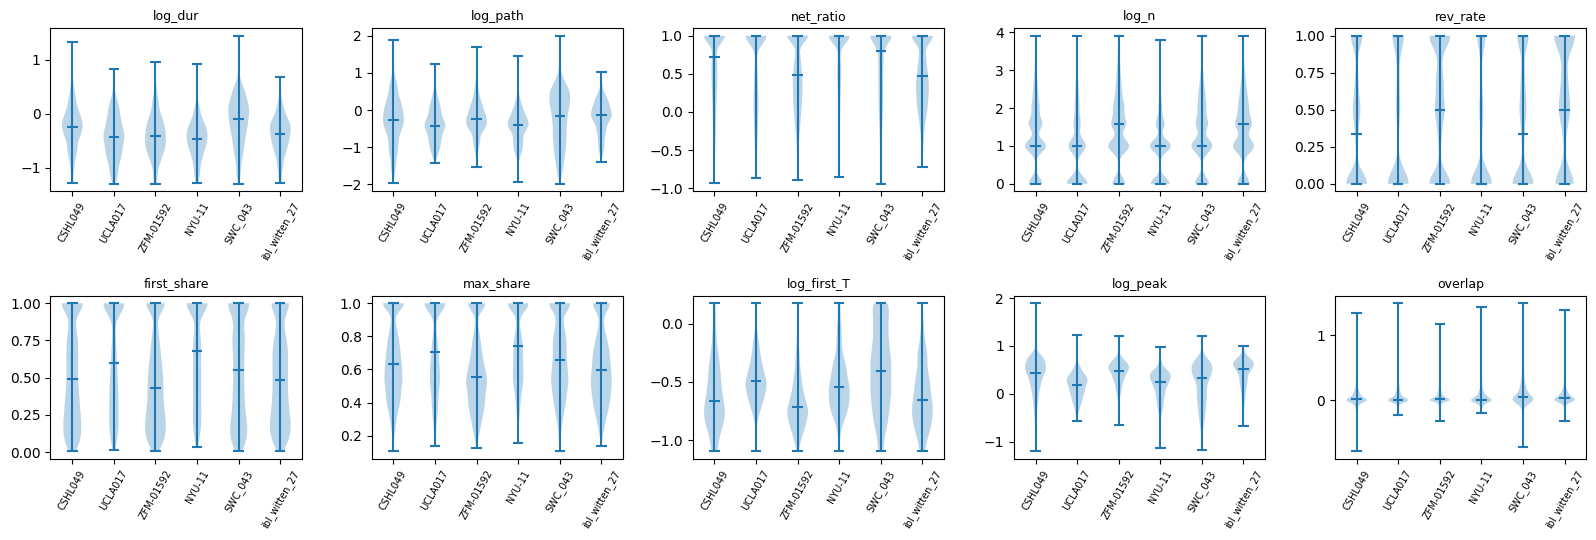

In [2]:
fig, axs = plt.subplots(2, 5, figsize=(16, 5.5))
for ax, f in zip(axs.flat, FEATS):
    ax.violinplot([M.loc[M.mouse == m, f] for m in MICE], showmedians=True)
    ax.set_xticks(range(1, len(MICE) + 1), MICE, rotation=60, fontsize=7); ax.set_title(f, fontsize=9)
plt.tight_layout()

## Gaussian mixture, K = 20

In [3]:
X = ((M[FEATS] - M[FEATS].mean()) / M[FEATS].std()).values
gmm = GaussianMixture(K, covariance_type='full', n_init=10, random_state=0).fit(X)
lab = gmm.predict(X)
order = M.groupby(lab).log_path.median().sort_values().index     # class 0 = smallest movements
M['cls'] = pd.Series(lab).map({c: i for i, c in enumerate(order)}).values
COL = plt.cm.tab20(np.arange(K) % 20)
summ = M.groupby('cls').agg(fraction=('cls', lambda x: len(x) / len(M)), n_prim=('n', 'median'),
                            dur_s=('log_dur', lambda x: 10 ** x.median()), path_rad=('log_path', lambda x: 10 ** x.median()),
                            net_ratio=('net_ratio', 'median'), rev_rate=('rev_rate', 'median'),
                            first_share=('first_share', 'median'), peak_rad_s=('log_peak', lambda x: 10 ** x.median()),
                            overlap_s=('overlap', 'median'))
summ.round(2)

,fraction,n_prim,dur_s,path_rad,net_ratio,rev_rate,first_share,peak_rad_s,overlap_s
cls,,,,,,,,,
0,0.01,1.0,0.09,0.03,1.00,0.00,1.00,0.26,0.00
1,0.07,2.0,0.26,0.18,1.00,0.00,0.33,1.09,0.05
2,0.12,1.0,0.15,0.22,1.00,0.00,1.00,1.37,0.00
3,0.12,1.0,0.25,0.22,1.00,0.00,1.00,1.67,0.00
4,0.08,2.0,0.38,0.41,1.00,0.00,0.71,2.14,0.12
5,0.05,2.0,0.41,0.42,-0.27,1.00,0.37,1.93,0.04
6,0.01,3.0,0.53,0.49,0.53,1.00,0.27,2.00,0.03
7,0.11,2.0,0.37,0.51,0.42,1.00,0.71,2.52,0.06
8,0.02,3.0,0.74,0.60,1.00,0.00,0.21,2.46,0.02


### Mean shape of each class (velocity time-normalised to the movement, flipped so the first primitive is positive)

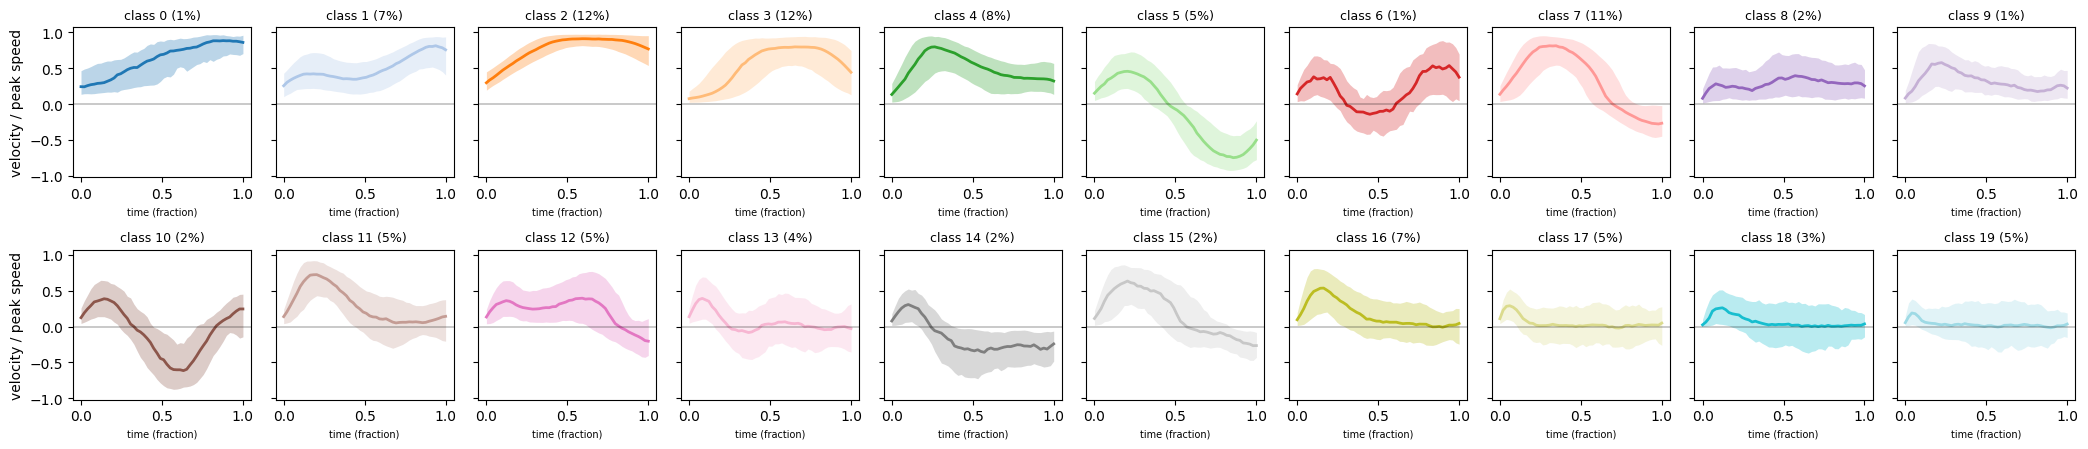

In [4]:
NT = 50
prof = {c: [] for c in range(K)}
for _, r in M.iterrows():
    dm = DM[r.eid]; t = dm.times.values
    i0, i1 = np.searchsorted(t, [r.onset, r.offset])
    if i1 - i0 < 3: continue
    vv = dm.velocity.values[i0:i1] * r.direction
    prof[r.cls].append(np.interp(np.linspace(0, 1, NT), np.linspace(0, 1, len(vv)), vv) / 10 ** r.log_peak)
fig, axs = plt.subplots(2, K // 2, figsize=(2.1 * K / 2, 4.6), sharey=True)
x = np.linspace(0, 1, NT)
for c, ax in enumerate(axs.flat):
    a = np.array(prof[c])
    ax.fill_between(x, *np.percentile(a, [25, 75], axis=0), color=COL[c], alpha=.3, lw=0)
    ax.plot(x, np.median(a, 0), color=COL[c], lw=2); ax.axhline(0, c='k', lw=.3)
    ax.set_title(f'class {c} ({summ.fraction[c]:.0%})', fontsize=9); ax.set_xlabel('time (fraction)', fontsize=7)
axs[0, 0].set_ylabel('velocity / peak speed'); axs[1, 0].set_ylabel('velocity / peak speed')
plt.tight_layout()

### Gallery: random movements of each class (grey = velocity, thin = its primitives; flipped so the first primitive is positive)

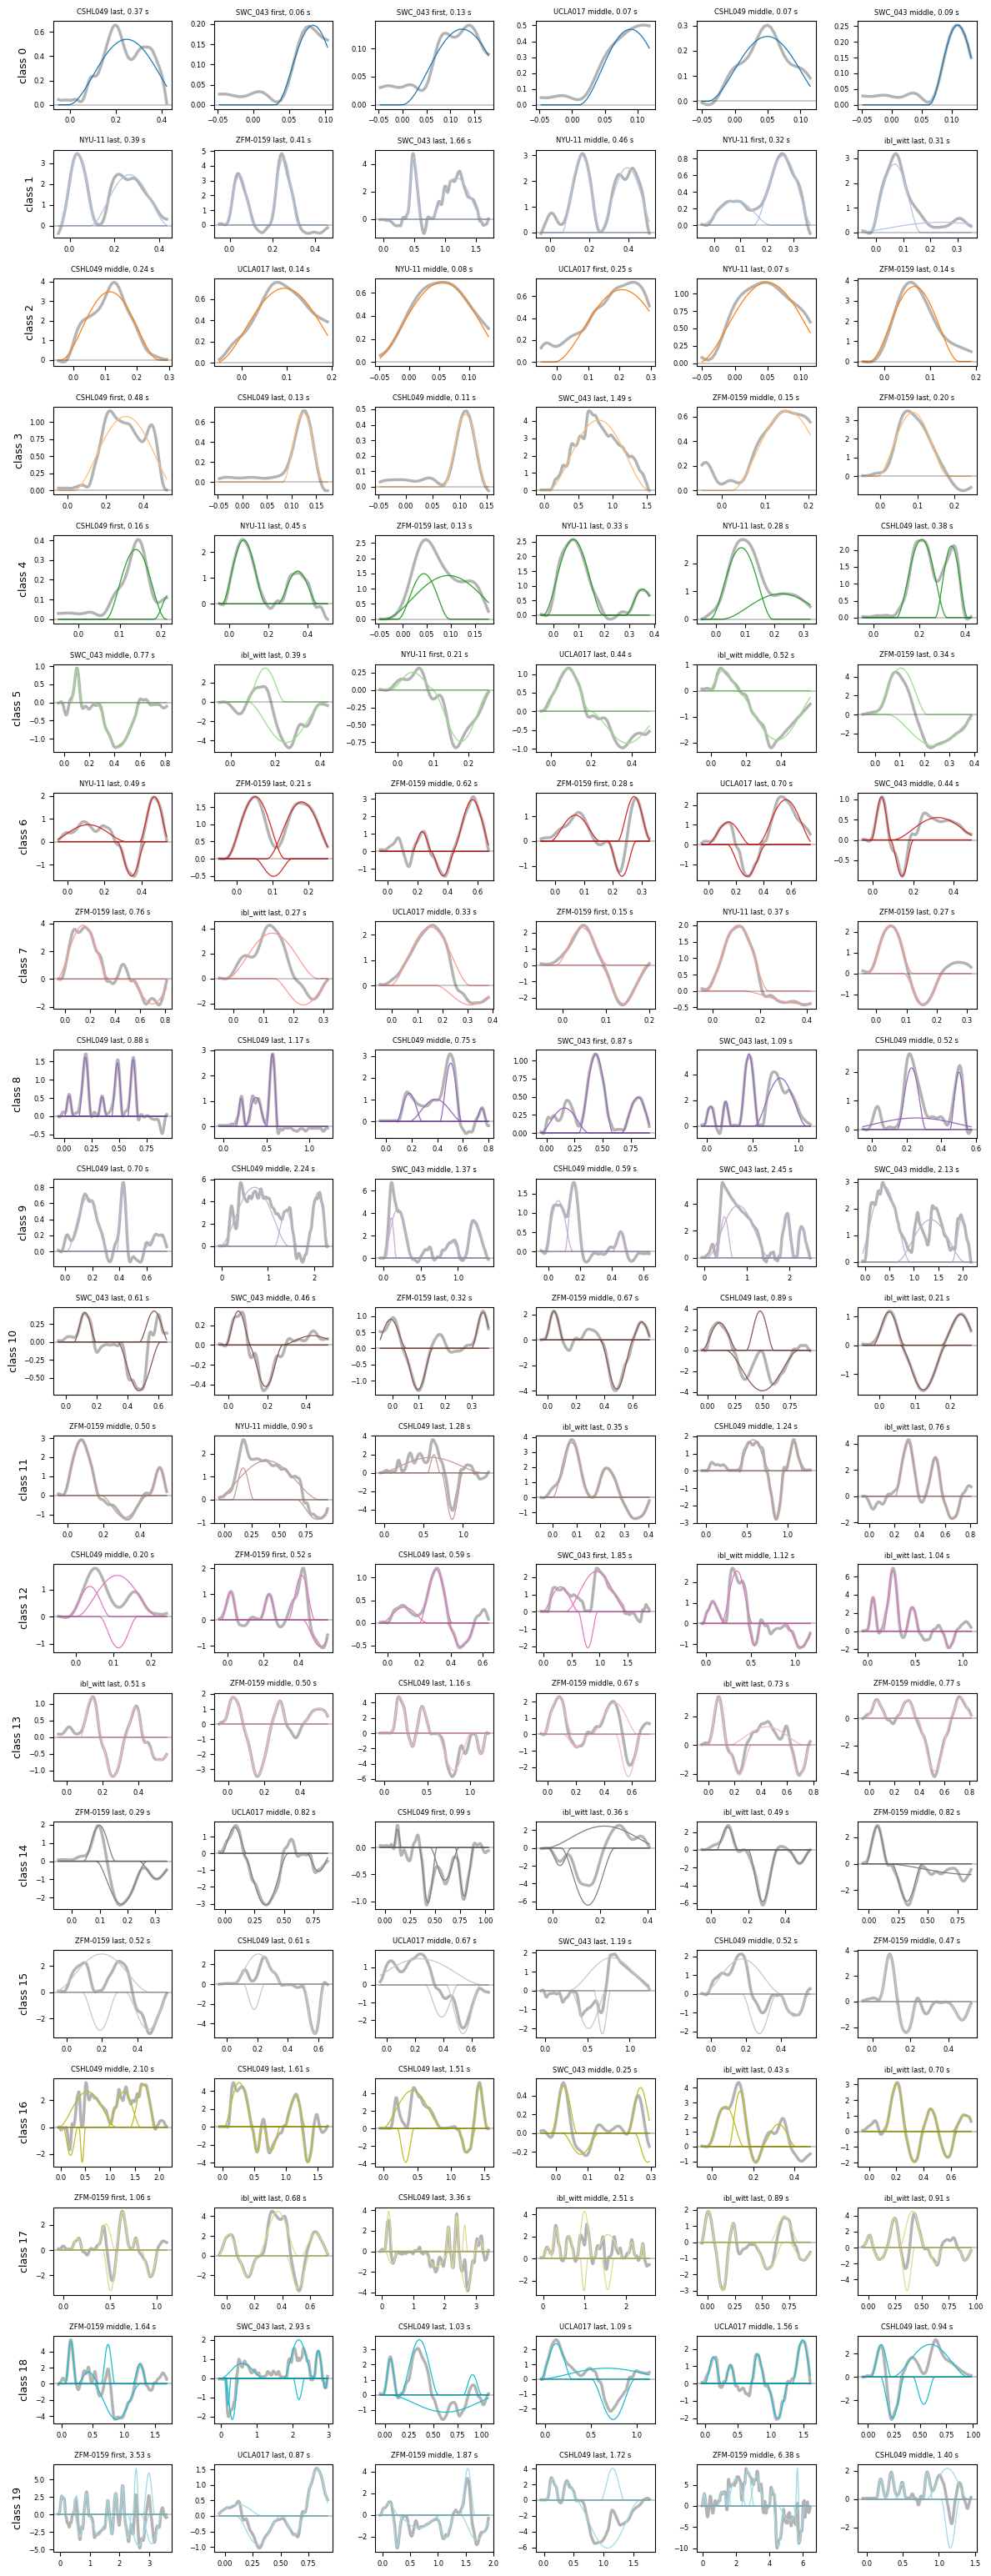

In [5]:
rng = np.random.default_rng(0)
N_EX = 6
fig, axs = plt.subplots(K, N_EX, figsize=(2 * N_EX, 1.55 * K), squeeze=False)
for c in range(K):
    idx = rng.choice(M.index[M.cls == c], min(N_EX, (M.cls == c).sum()), replace=False)
    for j, i in enumerate(idx):
        r = M.loc[i]; dm = DM[r.eid]; ax = axs[c, j]
        tt, vv = pr.movement_window(dm.times.values, dm.velocity.values, r.onset, r.offset)
        ax.plot(tt, vv * r.direction, c='0.7', lw=2.5)
        q = PR[r.eid].query('movement == @r.movement')
        for _, o in q.iterrows():
            ax.plot(tt, r.direction * pr.minjerk(tt + r.onset, o.start, o.duration, o.D), c=COL[c], lw=.9)
        ax.axhline(0, c='k', lw=.3); ax.tick_params(labelsize=6)
        ax.set_title(f'{r.mouse[:8]} {r.stage}, {10 ** r.log_dur:.2f} s', fontsize=6)
    axs[c, 0].set_ylabel(f'class {c}', fontsize=9)
plt.tight_layout()

## Are classes shared across mice? How does use change from first to last session?

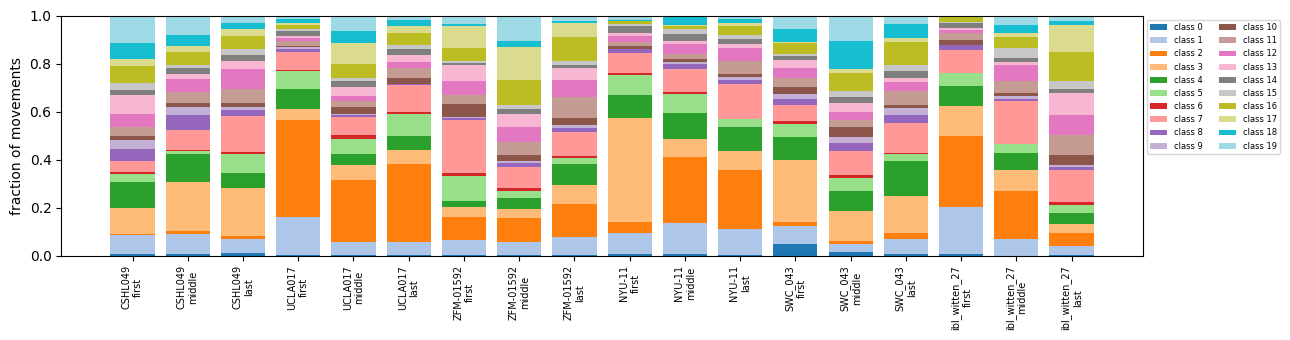

In [6]:
u = M.groupby(['mouse', 'stage'], sort=False).cls.value_counts(normalize=True).unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(13, 3.5))
bottom = np.zeros(len(u))
for c in range(K):
    ax.bar(range(len(u)), u[c], bottom=bottom, color=COL[c], label=f'class {c}'); bottom += u[c].values
ax.set_xticks(range(len(u)), [f'{m}\n{s}' for m, s in u.index], fontsize=7, rotation=90)
ax.set(ylabel='fraction of movements'); ax.legend(fontsize=6, ncol=2, bbox_to_anchor=(1, 1), loc='upper left')
plt.tight_layout()

In [7]:
# how much of the class assignment is just 'which mouse'? (0 = classes independent of mouse, 1 = each mouse its own classes)
from sklearn.metrics import normalized_mutual_info_score as nmi
print('NMI(class, mouse) =', round(nmi(M.mouse, M.cls), 3), '   NMI(class, stage) =', round(nmi(M.stage, M.cls), 3))
pd.crosstab(M.cls, M.mouse, normalize='columns').round(2)

NMI(class, mouse) = 0.053    NMI(class, stage) = 0.011


mouse,CSHL049,NYU-11,SWC_043,UCLA017,ZFM-01592,ibl_witten_27
cls,,,,,,
0,0.01,0.00,0.02,0.00,0.00,0.00
1,0.07,0.11,0.06,0.08,0.07,0.06
2,0.01,0.22,0.02,0.32,0.12,0.11
3,0.19,0.13,0.18,0.06,0.06,0.06
4,0.09,0.10,0.12,0.06,0.06,0.06
5,0.05,0.04,0.04,0.08,0.04,0.04
6,0.01,0.00,0.01,0.01,0.01,0.01
7,0.11,0.13,0.10,0.09,0.12,0.14
8,0.04,0.02,0.03,0.01,0.02,0.01


## Where in the trial does each class occur?

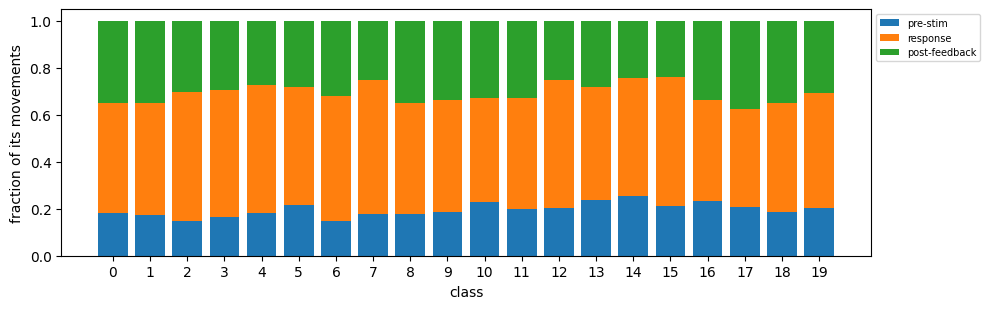

In [8]:
e = pd.crosstab(M.cls, M.epoch, normalize='index')[pr.EPOCHS]
fig, ax = plt.subplots(figsize=(10, 3.2))
bottom = np.zeros(K)
for ep, c in zip(pr.EPOCHS, ['tab:blue', 'tab:orange', 'tab:green']):
    ax.bar(range(K), e[ep], bottom=bottom, color=c, label=ep); bottom += e[ep].values
ax.set(xlabel='class', ylabel='fraction of its movements', xticks=range(K)); ax.legend(fontsize=7, bbox_to_anchor=(1, 1), loc='upper left')
plt.tight_layout()

## Classes in time: a stretch of trials, every movement shaded by its class

Black = measured velocity, thin coloured = fitted primitives, shading = the movement's class (number above it). Dashed blue = stimulus on, dashed red = feedback. Velocity is in wheel coordinates (not flipped).

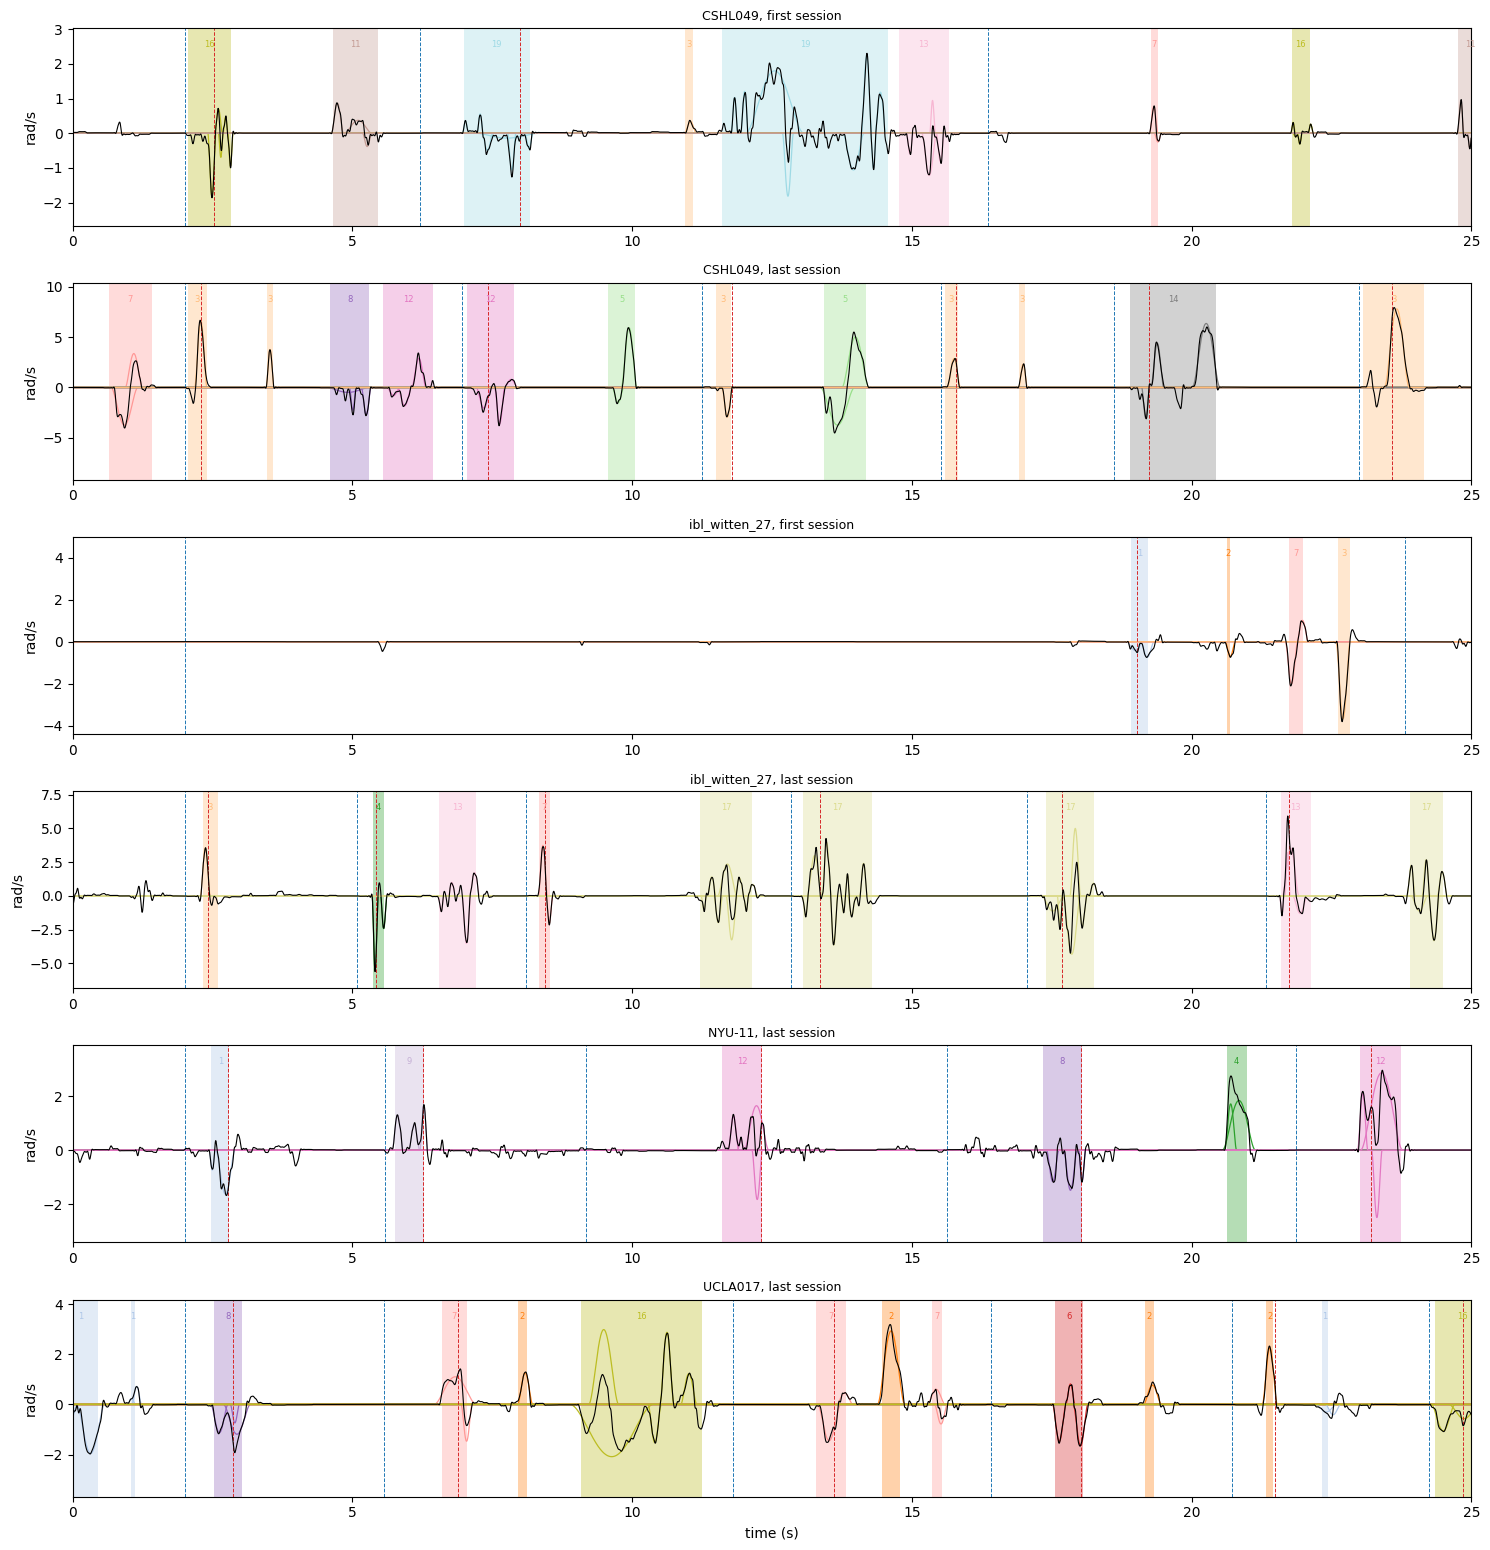

In [9]:
from one.api import ONE
one = ONE(mode='remote')
WIN = 25    # s
def class_timeline(mouse, stage, ax, t_from=0.4):
    q = M[(M.mouse == mouse) & (M.stage == stage)]
    eid = q.eid.iloc[0]; dm = DM[eid]; p = PR[eid]
    _, tr = ws.load_session(eid, mouse)
    tr['stim'] = pr.stim_times(tr)
    t0 = tr.stim.iloc[int(t_from * len(tr))] - 2
    sel = (dm.times > t0) & (dm.times < t0 + WIN)
    tt, vv = dm.times[sel].values, dm.velocity[sel].values
    ax.plot(tt - t0, vv, c='k', lw=.8, zorder=3)
    top = np.abs(vv).max() * 1.05
    for _, r in q[(q.onset < t0 + WIN) & (q.offset > t0)].iterrows():
        ax.axvspan(r.onset - t0, r.offset - t0, color=COL[r.cls], alpha=.35, lw=0)
        ax.text((r.onset + r.offset) / 2 - t0, top, str(r.cls), ha='center', va='bottom', fontsize=6, color=COL[r.cls])
        for _, o in p.query('movement == @r.movement').iterrows():
            ax.plot(tt - t0, pr.minjerk(tt, o.start, o.duration, o.D), c=COL[r.cls], lw=.9, zorder=2)
    for col, c in [('stim', 'tab:blue'), ('feedback_times', 'tab:red')]:
        for e in tr[col].values:
            if 0 < e - t0 < WIN: ax.axvline(e - t0, c=c, ls='--', lw=.7)
    ax.set(xlim=(0, WIN), ylim=(-top * 1.1, top * 1.25), ylabel='rad/s')
    ax.set_title(f'{mouse}, {stage} session', fontsize=9)

panels = [('CSHL049', 'first'), ('CSHL049', 'last'), ('ibl_witten_27', 'first'), ('ibl_witten_27', 'last'),
          ('NYU-11', 'last'), ('UCLA017', 'last')]
fig, axs = plt.subplots(len(panels), 1, figsize=(15, 2.6 * len(panels)))
for ax, (m, st) in zip(axs, panels):
    class_timeline(m, st, ax)
axs[-1].set_xlabel('time (s)')
plt.tight_layout()